# Assigment-1 DL
**ARTI 502 — Deep Learning | Assignment 1 | Academic Year: 2026 — Term 1**

Training-Testing Neural Net with MNIST Dataset using Pytorch

**Group Number:** 03

| # | Student Name | Academic ID |
|---|---|---|
| 1 | Reham Abdulaziz Almalki | 2230005182 |
| 2 | Sara Yousef Al-Saeed | 2230002553 |
| 3 | Zainab Yaseen Bukhamsin | 2230005840 |
| 4 | Lolwa Osama Almansori | 2230002781 |
| 5 | Albandri alshammri | 2230003975 |



## Task 1: Install PyTorch
PyTorch is already installed, so another installation is unnecessary. If starting on a new computer, install dependencies with `python -m pip install torch torchvision numpy matplotlib pandas ipykernel`. The following executed cell verifies the import and version.

In [12]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from torchvision import datasets
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pathlib import Path
import struct
import random
import time

%matplotlib inline
SEED = 502
torch.set_num_threads(4)
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
device = torch.device("cpu")
print("Assigment-1 DL")
print("PyTorch import successful:", torch.__version__)
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

Assigment-1 DL
PyTorch import successful: 2.11.0+cpu
Device: cpu
CUDA available: False


## Task 2: Download and Load the Dataset
The MNIST dataset is downloaded directly through Python using torchvision.datasets.MNIST with download=True. If the dataset has already been downloaded, PyTorch loads the existing files without downloading them again.

MNIST contains 60,000 training images and 10,000 testing images. Each image is a 28×28 grayscale image representing a handwritten digit from 0 to 9.

The original training dataset is divided into 50,000 training images and 10,000 validation images using a fixed random seed to ensure reproducibility. The official 10,000 testing images are kept separate for final evaluation.

The images are converted into PyTorch tensors and normalized to the range [0, 1]. TensorDataset and DataLoader are used to organize the data into mini-batches for training, validation, and testing.

In [13]:
DATA_DIR = Path("archive")

train_mnist = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True
)

test_mnist = datasets.MNIST(
    root=DATA_DIR,
    train=False,
    download=True
)

print("MNIST dataset downloaded or found in cache successfully!")

# Convert MNIST images to tensors normalized to [0, 1]
full_train_dataset = TensorDataset(
    train_mnist.data.unsqueeze(1).float() / 255.0,
    train_mnist.targets.long()
)

test_dataset = TensorDataset(
    test_mnist.data.unsqueeze(1).float() / 255.0,
    test_mnist.targets.long()
)

# Split 60,000 images into training and validation
train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

# Create DataLoaders
BATCH_SIZE = 32

def make_train_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        num_workers=0
    )

train_loader = make_train_loader(train_dataset)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=256,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

# Verify dataset loading
print("Official training images:", len(full_train_dataset))
print("Official testing images:", len(test_dataset))
print("Training split:", len(train_dataset))
print("Validation split:", len(validation_dataset))
print("Training batches:", len(train_loader))
print("Batch size:", BATCH_SIZE)

images, labels = next(iter(train_loader))
print("Images tensor shape:", images.shape)
print("Labels tensor shape:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())


MNIST dataset downloaded or found in cache successfully!
Official training images: 60000
Official testing images: 10000
Training split: 50000
Validation split: 10000
Training batches: 1563
Batch size: 32
Images tensor shape: torch.Size([32, 1, 28, 28])
Labels tensor shape: torch.Size([32])
Pixel range: 0.0 1.0


## Task 3: Inspect the Dataset
Inspect one shuffled training batch. Each image has one grayscale channel and each label is a digit from 0 to 9. The image titles show the labels supplied by the DataLoader.

One image tensor size: torch.Size([1, 28, 28])
Batch tensor dimensions: torch.Size([32, 1, 28, 28])
Label batch dimensions: torch.Size([32])
First 12 labels: [9, 1, 9, 1, 5, 4, 5, 7, 0, 1, 9, 2]
Image dtype: torch.float32 Label dtype: torch.int64
Pixel range: 0.0 1.0


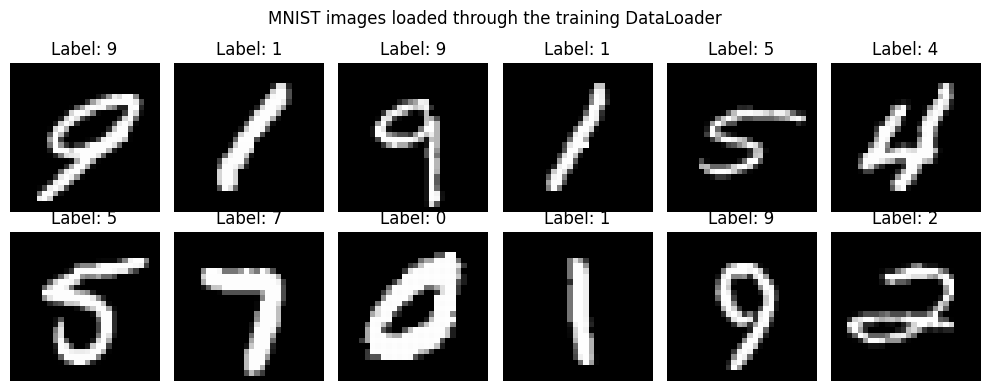

In [14]:
images, labels = next(iter(train_loader))
print("One image tensor size:", images[0].size())
print("Batch tensor dimensions:", images.size())
print("Label batch dimensions:", labels.size())
print("First 12 labels:", labels[:12].tolist())
print("Image dtype:", images.dtype, "Label dtype:", labels.dtype)
print("Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, image, label in zip(axes.flat, images[:12], labels[:12]):
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")
fig.suptitle("MNIST images loaded through the training DataLoader")
plt.tight_layout()
plt.show()

## Task 4: Creating A Simple Network
The baseline has exactly one hidden layer: Linear(784, 128), ReLU, and Linear(128, 10). `torch.flatten(x, start_dim=1)` preserves the batch dimension. Outputs are raw logits; CrossEntropyLoss applies the needed log-softmax internally.

In [15]:
class SimpleNetwork(nn.Module):
    def __init__(self, hidden_neurons=128):
        super().__init__()
        self.hidden = nn.Linear(28 * 28, hidden_neurons)
        self.relu = nn.ReLU()
        self.output = nn.Linear(hidden_neurons, 10)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.relu(self.hidden(x))
        return self.output(x)

demo_model = SimpleNetwork().to(device)
with torch.no_grad():
    demo_output = demo_model(images.to(device))
print(demo_model)
print("Input:", tuple(images.shape))
print("After torch.flatten:", tuple(torch.flatten(images, start_dim=1).shape))
print("Output logits:", tuple(demo_output.shape))
assert tuple(images.shape) == (32, 1, 28, 28)
assert tuple(demo_output.shape) == (32, 10)
assert sum(isinstance(layer, nn.Linear) for layer in demo_model.modules()) == 2

SimpleNetwork(
  (hidden): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=128, out_features=10, bias=True)
)
Input: (32, 1, 28, 28)
After torch.flatten: (32, 784)
Output logits: (32, 10)


## Task 5: Training Function
This reusable function receives a network and training DataLoader. It uses CrossEntropyLoss and SGD with configurable learning rate and momentum. For each batch it clears gradients, performs the forward pass, calculates loss, backpropagates, and updates parameters. Epoch loss is weighted by the number of examples; accuracy is correct predictions divided by examples. Mini-batch losses are also returned.

In [16]:
def train(model, dataloader, epochs=8, learning_rate=0.01,
          momentum=0.9, verbose=True, log_every=400):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate,
                                momentum=momentum)
    history = {"epoch_loss": [], "epoch_accuracy": [], "batch_losses": []}
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for batch_number, (inputs, targets) in enumerate(dataloader, 1):
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            batch_correct = (logits.argmax(1) == targets).sum().item()
            total_loss += loss.item() * targets.size(0)
            correct += batch_correct
            total += targets.size(0)
            history["batch_losses"].append(loss.item())
            if verbose and (batch_number == 1 or batch_number % log_every == 0
                            or batch_number == len(dataloader)):
                print(f"Epoch {epoch}/{epochs} | Batch {batch_number}/{len(dataloader)} "
                      f"| Loss {loss.item():.4f} "
                      f"| Accuracy {100 * batch_correct / targets.size(0):.2f}%")
        history["epoch_loss"].append(total_loss / total)
        history["epoch_accuracy"].append(100 * correct / total)
        print(f"Epoch {epoch}/{epochs} complete | Mean loss {total_loss / total:.4f} "
              f"| Training accuracy {100 * correct / total:.2f}%")
    return history

print("Training function defined: CrossEntropyLoss + SGD; learning rate and momentum configurable.")

Training function defined: CrossEntropyLoss + SGD; learning rate and momentum configurable.


## Task 6: Training Network
A newly instantiated one-hidden-layer network trains for eight epochs on the 50,000-image training split. The baseline learning rate is 0.01, momentum is 0.9, and batch size is 32. Logging includes current mini-batch values and sample-weighted epoch summaries.

In [17]:
EPOCHS = 8
set_seed()
baseline_model = SimpleNetwork(hidden_neurons=128).to(device)
print("New baseline model:", baseline_model)
start = time.perf_counter()
baseline_history = train(baseline_model, make_train_loader(train_dataset),
                         epochs=EPOCHS, learning_rate=0.01, momentum=0.9)
print(f"Baseline training time: {time.perf_counter() - start:.1f} seconds")
print("Recorded mini-batch losses:", len(baseline_history["batch_losses"]))

New baseline model: SimpleNetwork(
  (hidden): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=128, out_features=10, bias=True)
)
Epoch 1/8 | Batch 1/1563 | Loss 2.2847 | Accuracy 9.38%
Epoch 1/8 | Batch 400/1563 | Loss 0.3737 | Accuracy 84.38%
Epoch 1/8 | Batch 800/1563 | Loss 0.4078 | Accuracy 81.25%
Epoch 1/8 | Batch 1200/1563 | Loss 0.2210 | Accuracy 90.62%
Epoch 1/8 | Batch 1563/1563 | Loss 0.0708 | Accuracy 100.00%
Epoch 1/8 complete | Mean loss 0.3855 | Training accuracy 89.29%
Epoch 2/8 | Batch 1/1563 | Loss 0.1163 | Accuracy 96.88%
Epoch 2/8 | Batch 400/1563 | Loss 0.1807 | Accuracy 93.75%
Epoch 2/8 | Batch 800/1563 | Loss 0.3683 | Accuracy 90.62%
Epoch 2/8 | Batch 1200/1563 | Loss 0.1694 | Accuracy 96.88%
Epoch 2/8 | Batch 1563/1563 | Loss 0.0748 | Accuracy 100.00%
Epoch 2/8 complete | Mean loss 0.1774 | Training accuracy 94.93%
Epoch 3/8 | Batch 1/1563 | Loss 0.1366 | Accuracy 90.62%
Epoch 3/8 | Batch 400/1563 | Loss 0.280

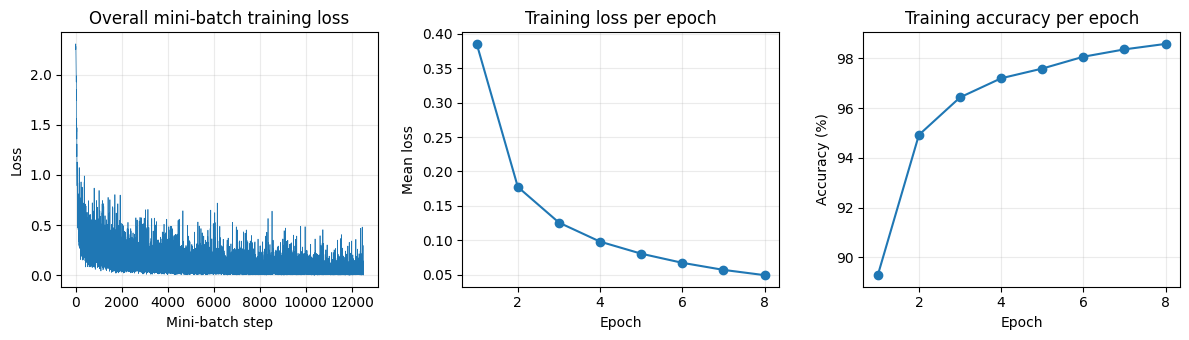

Loss: 0.3855 -> 0.0492
Training accuracy: 89.29% -> 98.58%


In [18]:
epoch_numbers = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].plot(baseline_history["batch_losses"], linewidth=0.5)
axes[0].set(title="Overall mini-batch training loss", xlabel="Mini-batch step", ylabel="Loss")
axes[1].plot(epoch_numbers, baseline_history["epoch_loss"], marker="o")
axes[1].set(title="Training loss per epoch", xlabel="Epoch", ylabel="Mean loss")
axes[2].plot(epoch_numbers, baseline_history["epoch_accuracy"], marker="o")
axes[2].set(title="Training accuracy per epoch", xlabel="Epoch", ylabel="Accuracy (%)")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Loss: {baseline_history['epoch_loss'][0]:.4f} -> {baseline_history['epoch_loss'][-1]:.4f}")
print(f"Training accuracy: {baseline_history['epoch_accuracy'][0]:.2f}% -> "
      f"{baseline_history['epoch_accuracy'][-1]:.2f}%")

Measured baseline training loss decreased from **0.3855** to **0.0492** and epoch training accuracy increased from **89.29%** to **98.58%**. The official baseline test accuracy in Task 7 is **97.51%** with test loss **0.0784**.

## Task 7: Testing Network
Evaluation uses `model.eval()` and `torch.no_grad()`. Test loss is averaged over all test examples, and test accuracy counts all correct predictions. Images below deliberately include correct and incorrect predictions where available, so the figure illustrates both kinds of outcome rather than estimating accuracy.

In [19]:
@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct, total = 0.0, 0, 0
    actual_labels, predicted_labels = [], []
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        logits = model(inputs)
        predictions = logits.argmax(dim=1)
        total_loss += criterion(logits, targets).item()
        correct += (predictions == targets).sum().item()
        total += targets.size(0)
        actual_labels.append(targets.cpu())
        predicted_labels.append(predictions.cpu())
    return {"loss": total_loss / total, "accuracy": 100 * correct / total,
            "correct": correct, "count": total,
            "actual": torch.cat(actual_labels), "predicted": torch.cat(predicted_labels)}

baseline_test = evaluate(baseline_model, test_loader)
print("Official test images:", baseline_test["count"])
print(f"Baseline test loss: {baseline_test['loss']:.4f}")
print(f"Baseline test accuracy: {baseline_test['accuracy']:.2f}% "
      f"({baseline_test['correct']}/{baseline_test['count']})")
print("First 20 actual labels:   ", baseline_test["actual"][:20].tolist())
print("First 20 predicted labels:", baseline_test["predicted"][:20].tolist())

Official test images: 10000
Baseline test loss: 0.0784
Baseline test accuracy: 97.51% (9751/10000)
First 20 actual labels:    [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4]
First 20 predicted labels: [7, 2, 1, 0, 4, 1, 4, 9, 6, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4]


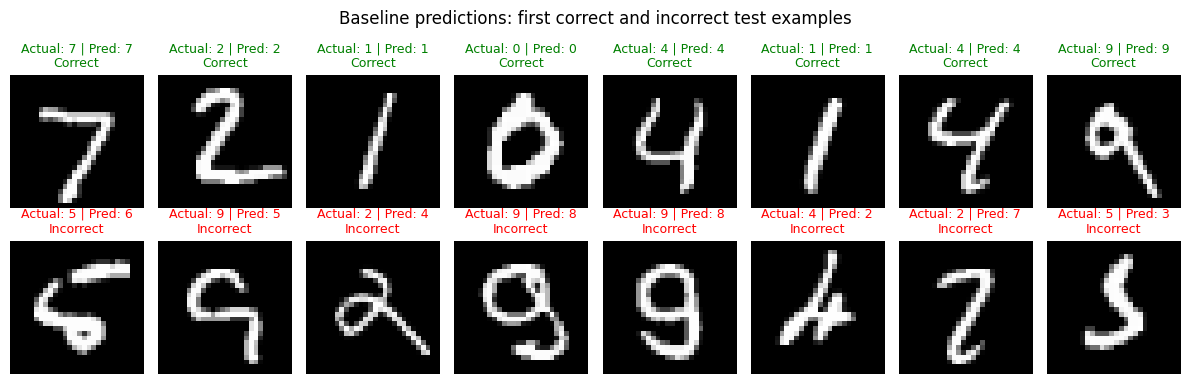

In [20]:
is_correct = baseline_test["actual"] == baseline_test["predicted"]
correct_indices = torch.where(is_correct)[0][:8]
wrong_indices = torch.where(~is_correct)[0][:8]
selected_indices = torch.cat((correct_indices, wrong_indices))
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, selected_indices.tolist()):
    image, actual = test_dataset[index]
    predicted = baseline_test["predicted"][index].item()
    correct_prediction = actual.item() == predicted
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Actual: {actual.item()} | Pred: {predicted}\n"
                 + ("Correct" if correct_prediction else "Incorrect"),
                 color="green" if correct_prediction else "red", fontsize=9)
fig.suptitle("Baseline predictions: first correct and incorrect test examples")
plt.tight_layout()
plt.show()

## Task 8: Tuning the parameters and model architecture
Eight controlled experiments change learning rate, momentum, hidden-layer count, and hidden-layer width. Each experiment uses the same 50,000/10,000 training/validation split, seed, shuffled batch order, batch size 32, and eight epochs. Each changes one choice relative to the baseline. We select by highest validation accuracy, breaking ties by lowest validation loss; the lowest-loss configuration is also reported if different. These results describe the tested configurations, not a global optimum. The official test set is not used for selection.

In [21]:
class TunableNetwork(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()
        layers = []
        input_size = 784
        for hidden_size in hidden_sizes:
            layers.extend([nn.Linear(input_size, hidden_size), nn.ReLU()])
            input_size = hidden_size
        layers.append(nn.Linear(input_size, 10))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(torch.flatten(x, start_dim=1))

configurations = [
    {"name": "Baseline",       "lr": 0.01,  "momentum": 0.9, "hidden": [128]},
    {"name": "Lower LR",       "lr": 0.001, "momentum": 0.9, "hidden": [128]},
    {"name": "Higher LR",      "lr": 0.05,  "momentum": 0.9, "hidden": [128]},
    {"name": "No momentum",    "lr": 0.01,  "momentum": 0.0, "hidden": [128]},
    {"name": "Lower momentum", "lr": 0.01,  "momentum": 0.5, "hidden": [128]},
    {"name": "Two hidden layers", "lr": 0.01, "momentum": 0.9, "hidden": [128, 64]},
    {"name": "Fewer neurons",  "lr": 0.01,  "momentum": 0.9, "hidden": [64]},
    {"name": "More neurons",   "lr": 0.01,  "momentum": 0.9, "hidden": [256]},
]
results = []
for config in configurations:
    print("\nExperiment:", config)
    set_seed()
    model = (SimpleNetwork(config["hidden"][0]) if len(config["hidden"]) == 1
             else TunableNetwork(config["hidden"])) .to(device)
    history = train(model, make_train_loader(train_dataset), epochs=EPOCHS,
                    learning_rate=config["lr"], momentum=config["momentum"], verbose=False)
    validation = evaluate(model, validation_loader)
    results.append({"Configuration": config["name"], "Learning rate": config["lr"],
                    "Momentum": config["momentum"], "Hidden layers": len(config["hidden"]),
                    "Neurons per layer": str(config["hidden"]),
                    "Train loss": history["epoch_loss"][-1],
                    "Train accuracy (%)": history["epoch_accuracy"][-1],
                    "Validation loss": validation["loss"],
                    "Validation accuracy (%)": validation["accuracy"]})
    print(f"Validation loss: {validation['loss']:.4f}; accuracy: {validation['accuracy']:.2f}%")

results_table = pd.DataFrame(results)
display(results_table.round(4))
best_row = results_table.sort_values(
    ["Validation accuracy (%)", "Validation loss"], ascending=[False, True]).iloc[0]
lowest_loss_row = results_table.sort_values("Validation loss").iloc[0]
best_config = next(c for c in configurations if c["name"] == best_row["Configuration"])
print("Best by validation accuracy (then loss):", best_config)
print(f"Best validation accuracy: {best_row['Validation accuracy (%)']:.2f}%")
print(f"Corresponding validation loss: {best_row['Validation loss']:.4f}")
print("Lowest validation loss configuration:", lowest_loss_row["Configuration"],
      f"(loss {lowest_loss_row['Validation loss']:.4f}, "
      f"accuracy {lowest_loss_row['Validation accuracy (%)']:.2f}%)")


Experiment: {'name': 'Baseline', 'lr': 0.01, 'momentum': 0.9, 'hidden': [128]}
Epoch 1/8 complete | Mean loss 0.3855 | Training accuracy 89.29%
Epoch 2/8 complete | Mean loss 0.1774 | Training accuracy 94.93%
Epoch 3/8 complete | Mean loss 0.1256 | Training accuracy 96.43%
Epoch 4/8 complete | Mean loss 0.0980 | Training accuracy 97.20%
Epoch 5/8 complete | Mean loss 0.0804 | Training accuracy 97.59%
Epoch 6/8 complete | Mean loss 0.0672 | Training accuracy 98.07%
Epoch 7/8 complete | Mean loss 0.0569 | Training accuracy 98.36%
Epoch 8/8 complete | Mean loss 0.0492 | Training accuracy 98.58%
Validation loss: 0.0878; accuracy: 97.46%

Experiment: {'name': 'Lower LR', 'lr': 0.001, 'momentum': 0.9, 'hidden': [128]}
Epoch 1/8 complete | Mean loss 0.9592 | Training accuracy 78.53%
Epoch 2/8 complete | Mean loss 0.3980 | Training accuracy 89.15%
Epoch 3/8 complete | Mean loss 0.3376 | Training accuracy 90.55%
Epoch 4/8 complete | Mean loss 0.3079 | Training accuracy 91.30%
Epoch 5/8 complet

,Configuration,Learning rate,Momentum,Hidden layers,Neurons per layer,Train loss,Train accuracy (%),Validation loss,Validation accuracy (%)
0,Baseline,0.010,0.9,1,[128],0.0492,98.584,0.0878,97.46
1,Lower LR,0.001,0.9,1,[128],0.2358,93.384,0.2363,93.16
2,Higher LR,0.050,0.9,1,[128],0.0271,99.082,0.1063,97.45
3,No momentum,0.010,0.0,1,[128],0.2354,93.384,0.2359,93.17
4,Lower momentum,0.010,0.5,1,[128],0.1623,95.500,0.1683,94.95
5,Two hidden layers,0.010,0.9,2,"[128, 64]",0.0339,98.946,0.0904,97.49
6,Fewer neurons,0.010,0.9,1,[64],0.0600,98.146,0.0981,96.94
7,More neurons,0.010,0.9,1,[256],0.0436,98.808,0.0794,97.56


Best by validation accuracy (then loss): {'name': 'More neurons', 'lr': 0.01, 'momentum': 0.9, 'hidden': [256]}
Best validation accuracy: 97.56%
Corresponding validation loss: 0.0794
Lowest validation loss configuration: More neurons (loss 0.0794, accuracy 97.56%)


In [22]:
base = results_table.iloc[0]
print("Measured changes relative to baseline (positive accuracy change is better):")
for _, row in results_table.iloc[1:].iterrows():
    accuracy_change = row["Validation accuracy (%)"] - base["Validation accuracy (%)"]
    loss_change = row["Validation loss"] - base["Validation loss"]
    print(f"{row['Configuration']}: accuracy {accuracy_change:+.2f} percentage points; "
          f"loss {loss_change:+.4f}")
print("Fixed epoch budget: a slower configuration may need more epochs.")
print("A deeper or wider network is only better here when the recorded validation results improve.")

Measured changes relative to baseline (positive accuracy change is better):
Lower LR: accuracy -4.30 percentage points; loss +0.1485
Higher LR: accuracy -0.01 percentage points; loss +0.0185
No momentum: accuracy -4.29 percentage points; loss +0.1481
Lower momentum: accuracy -2.51 percentage points; loss +0.0805
Two hidden layers: accuracy +0.03 percentage points; loss +0.0026
Fewer neurons: accuracy -0.52 percentage points; loss +0.0103
More neurons: accuracy +0.10 percentage points; loss -0.0084
Fixed epoch budget: a slower configuration may need more epochs.
A deeper or wider network is only better here when the recorded validation results improve.


Measured interpretation: lowering the learning rate to 0.001 reduced validation accuracy by 4.30 percentage points; raising it to 0.05 reduced accuracy by 0.01 points and increased loss by 0.0185. Momentum 0 and 0.5 performed worse than 0.9 within the eight-epoch budget (-4.29 and -2.51 points). Two hidden layers gained 0.03 points of accuracy but had slightly higher loss (+0.0026), so depth did not improve both measures. Reducing width to 64 lost 0.52 points; increasing width to 256 gained 0.10 points and reduced loss by 0.0084. These small gains are measured observations, not proof of statistical significance.

The selected one-hidden-layer, 256-neuron model (learning rate 0.01, momentum 0.9) achieved both the highest validation accuracy, **97.56%**, and lowest validation loss, **0.0794**, among the tested configurations.

After selection is complete, retrain a new model with the selected configuration on all 60,000 original training images for the same eight epochs. Then evaluate the final model once on the official test set. This final run uses more training data than the baseline, so any test improvement cannot be attributed solely to the tuned settings. A single seeded run per configuration provides a manageable coursework comparison, without claiming statistical significance.

In [23]:
set_seed()
final_model = (SimpleNetwork(best_config["hidden"][0]) if len(best_config["hidden"]) == 1
               else TunableNetwork(best_config["hidden"])) .to(device)
print("Selected configuration:", best_config)
print(final_model)
final_history = train(final_model, make_train_loader(full_train_dataset), epochs=EPOCHS,
                      learning_rate=best_config["lr"], momentum=best_config["momentum"],
                      verbose=False)
final_test = evaluate(final_model, test_loader)
print(f"Final training accuracy: {final_history['epoch_accuracy'][-1]:.2f}%")
print(f"Final test loss: {final_test['loss']:.4f}")
print(f"Final test accuracy: {final_test['accuracy']:.2f}% "
      f"({final_test['correct']}/{final_test['count']})")

Selected configuration: {'name': 'More neurons', 'lr': 0.01, 'momentum': 0.9, 'hidden': [256]}
SimpleNetwork(
  (hidden): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=256, out_features=10, bias=True)
)


Epoch 1/8 complete | Mean loss 0.3548 | Training accuracy 89.94%
Epoch 2/8 complete | Mean loss 0.1566 | Training accuracy 95.52%
Epoch 3/8 complete | Mean loss 0.1083 | Training accuracy 96.85%
Epoch 4/8 complete | Mean loss 0.0829 | Training accuracy 97.53%
Epoch 5/8 complete | Mean loss 0.0665 | Training accuracy 98.08%
Epoch 6/8 complete | Mean loss 0.0543 | Training accuracy 98.45%
Epoch 7/8 complete | Mean loss 0.0456 | Training accuracy 98.75%
Epoch 8/8 complete | Mean loss 0.0385 | Training accuracy 98.96%
Final training accuracy: 98.96%
Final test loss: 0.0638
Final test accuracy: 98.00% (9800/10000)


The final model reached **98.96%** training accuracy in epoch 8 and **98.00%** official test accuracy (9,800/10,000 correct), with test loss **0.0638**. The final model uses 60,000 training examples, whereas the baseline uses 50,000; this affects the comparison.